✅ Dataset Ingested from seasonal_agriculture_performance_dataset.csv | Matrix Shape: (4000, 28)
✅ Preprocessing Completed. Dataset Dimensions: (4000, 34)

SECTION 4: EXPLORATORY DATA ANALYSIS & VISUALIZATION DASHBOARDS


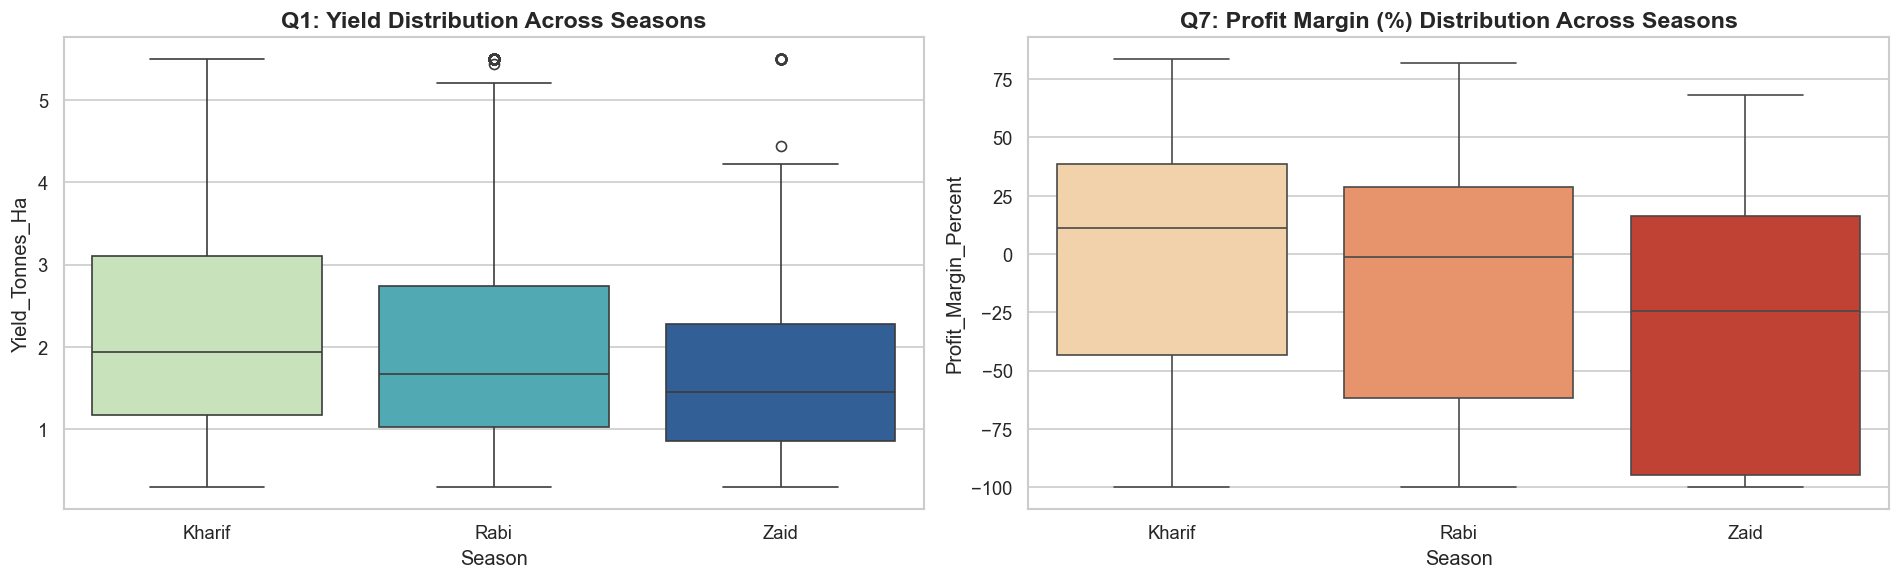

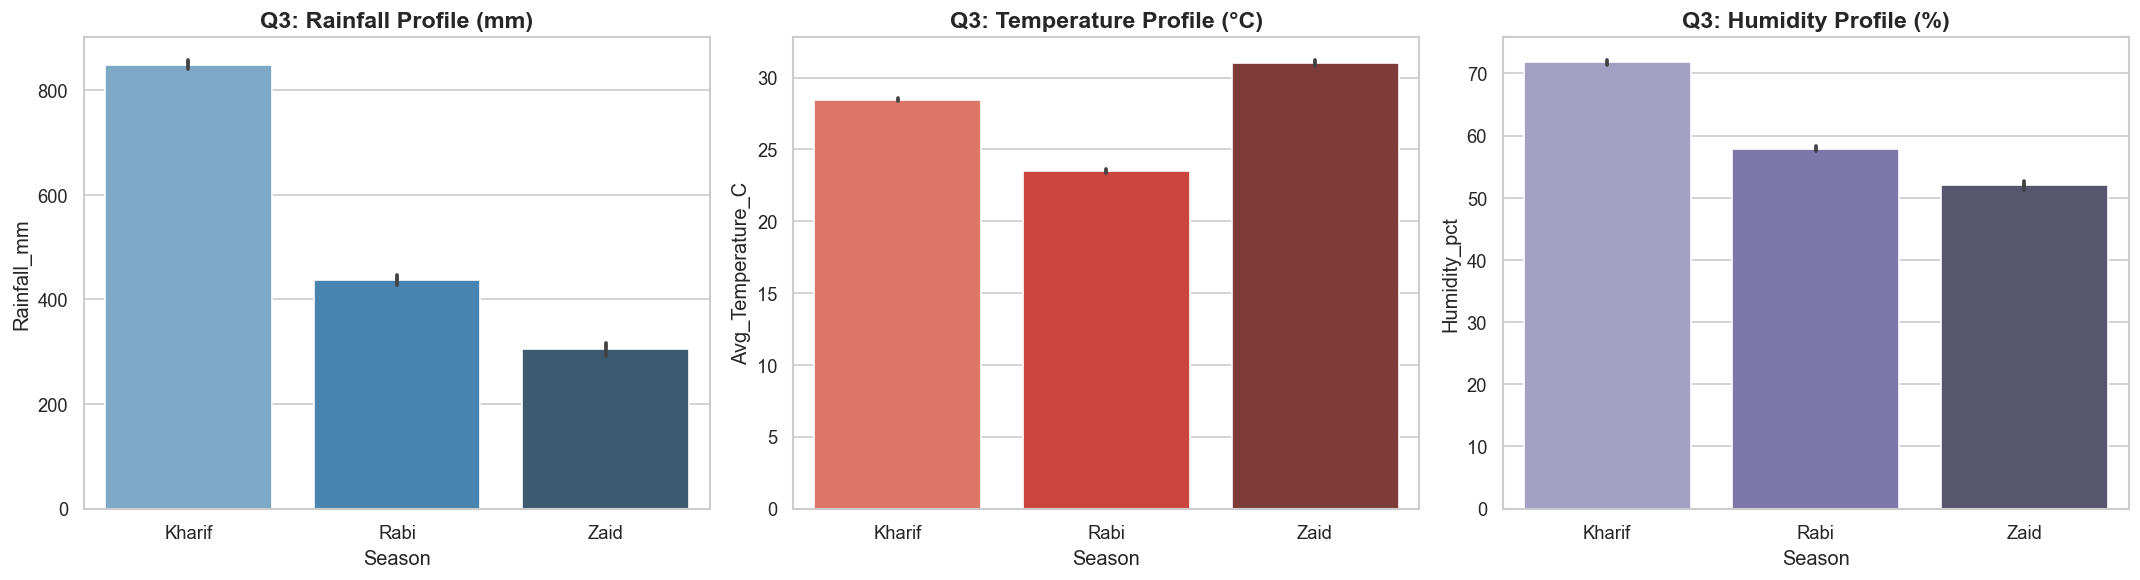

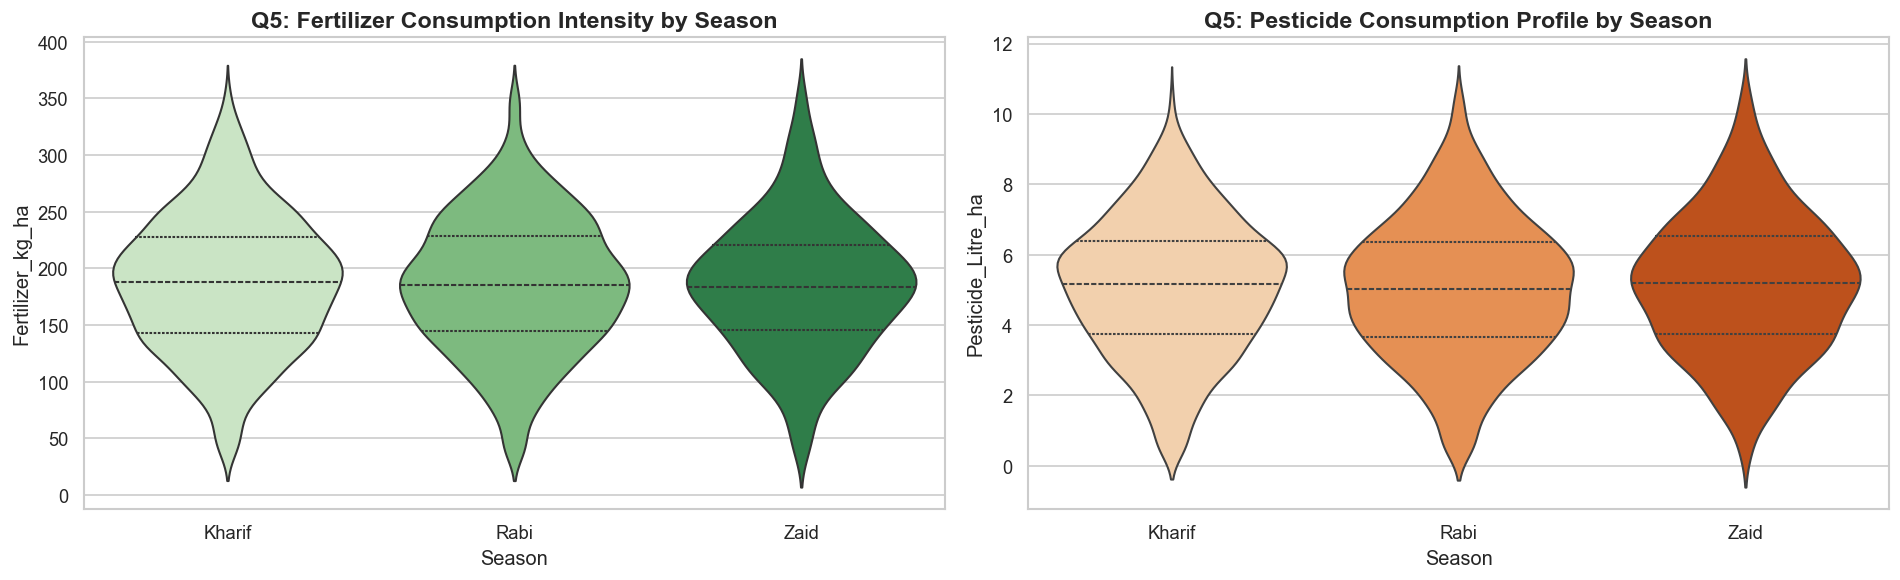

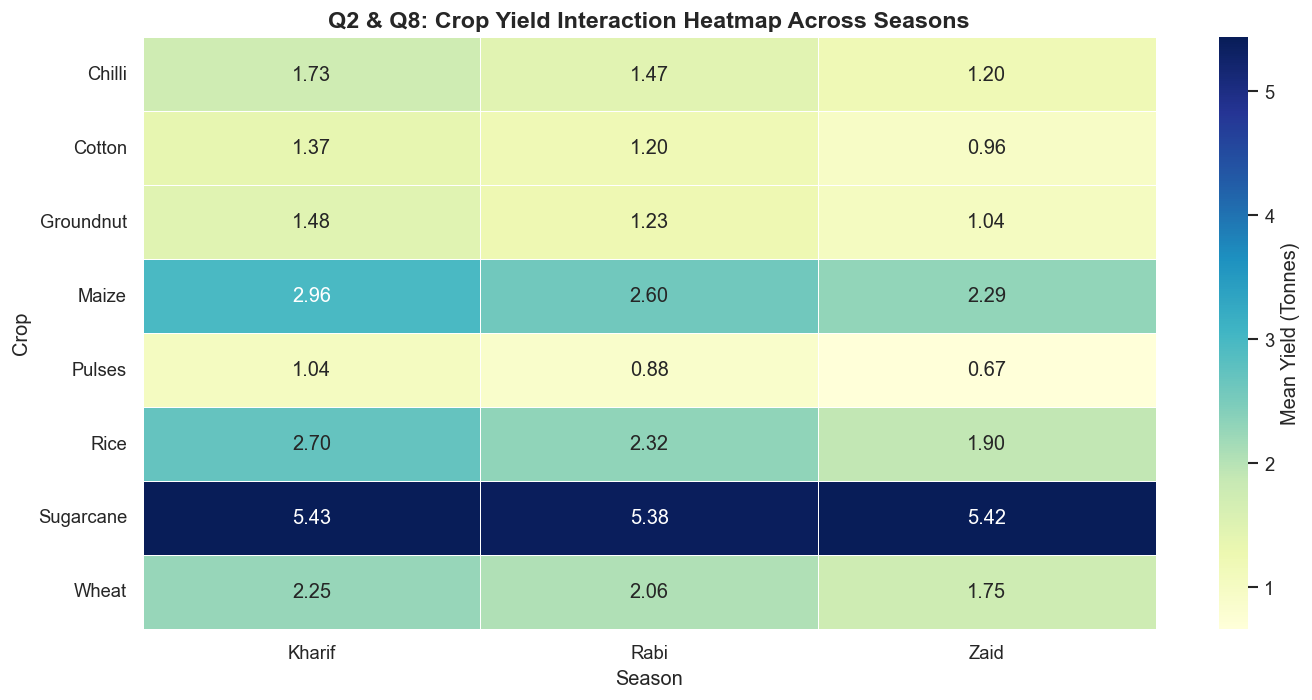

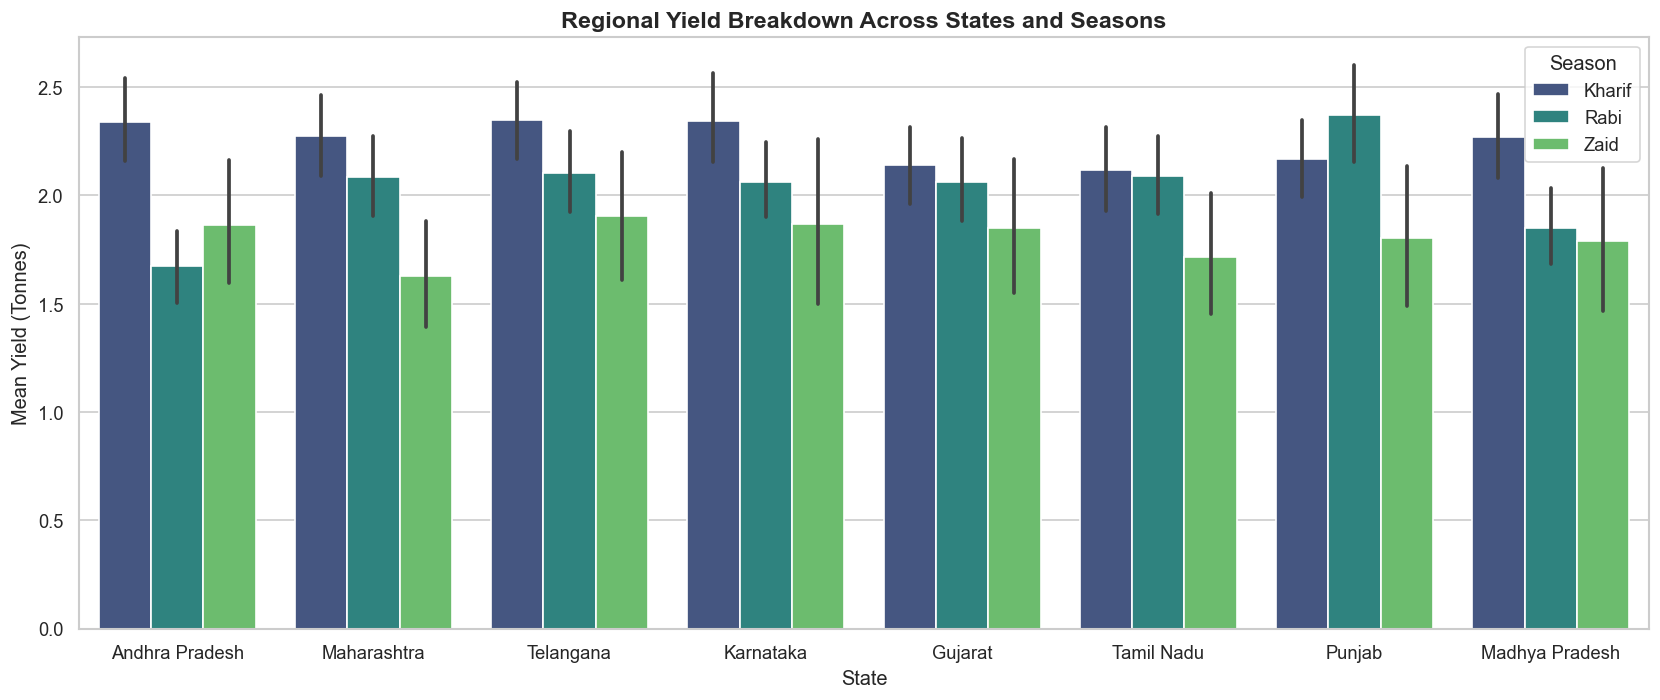

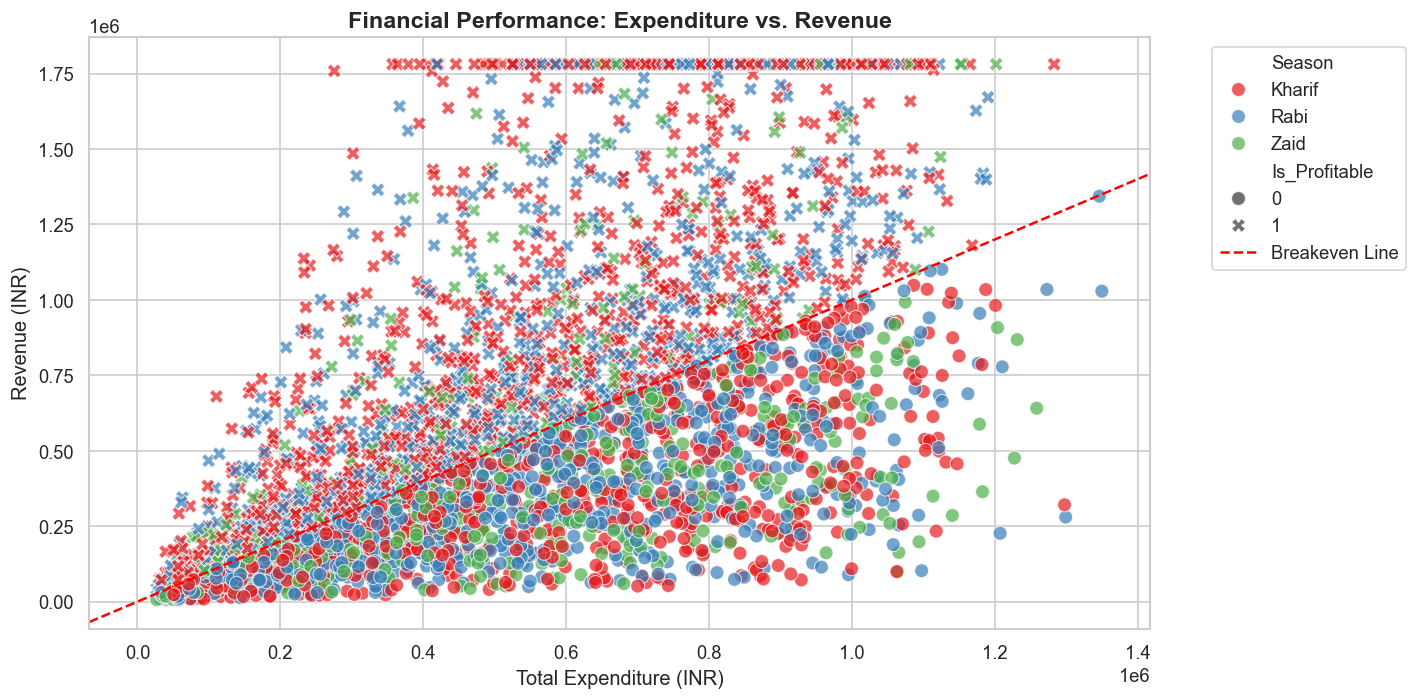

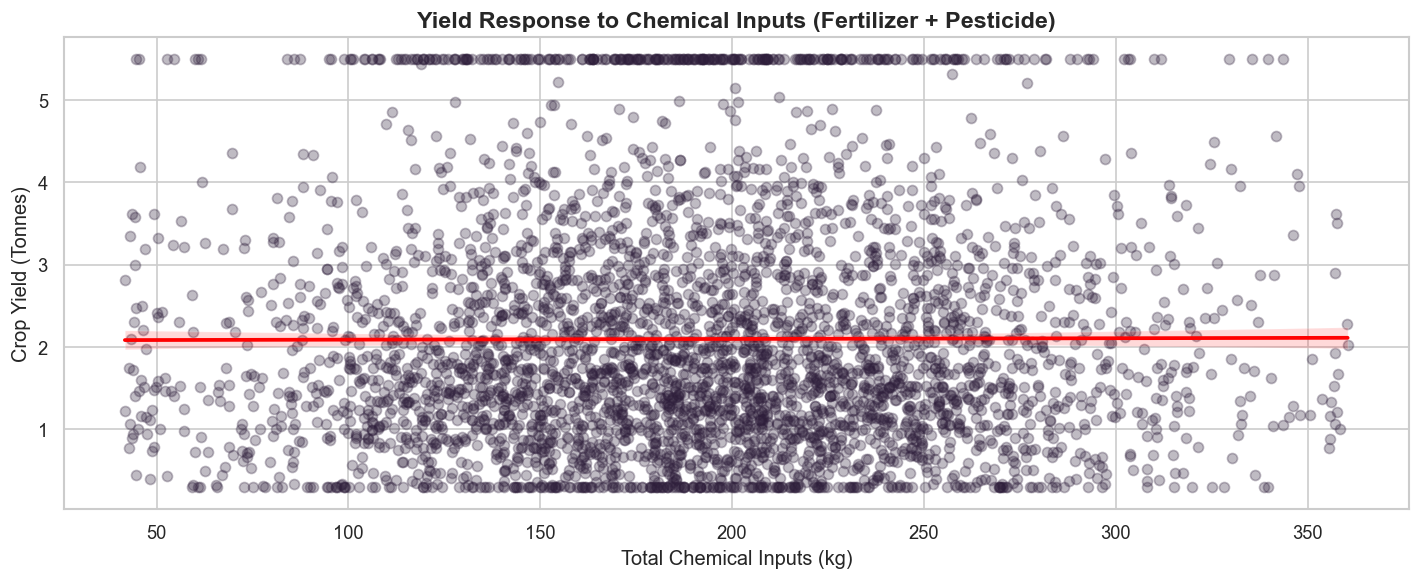

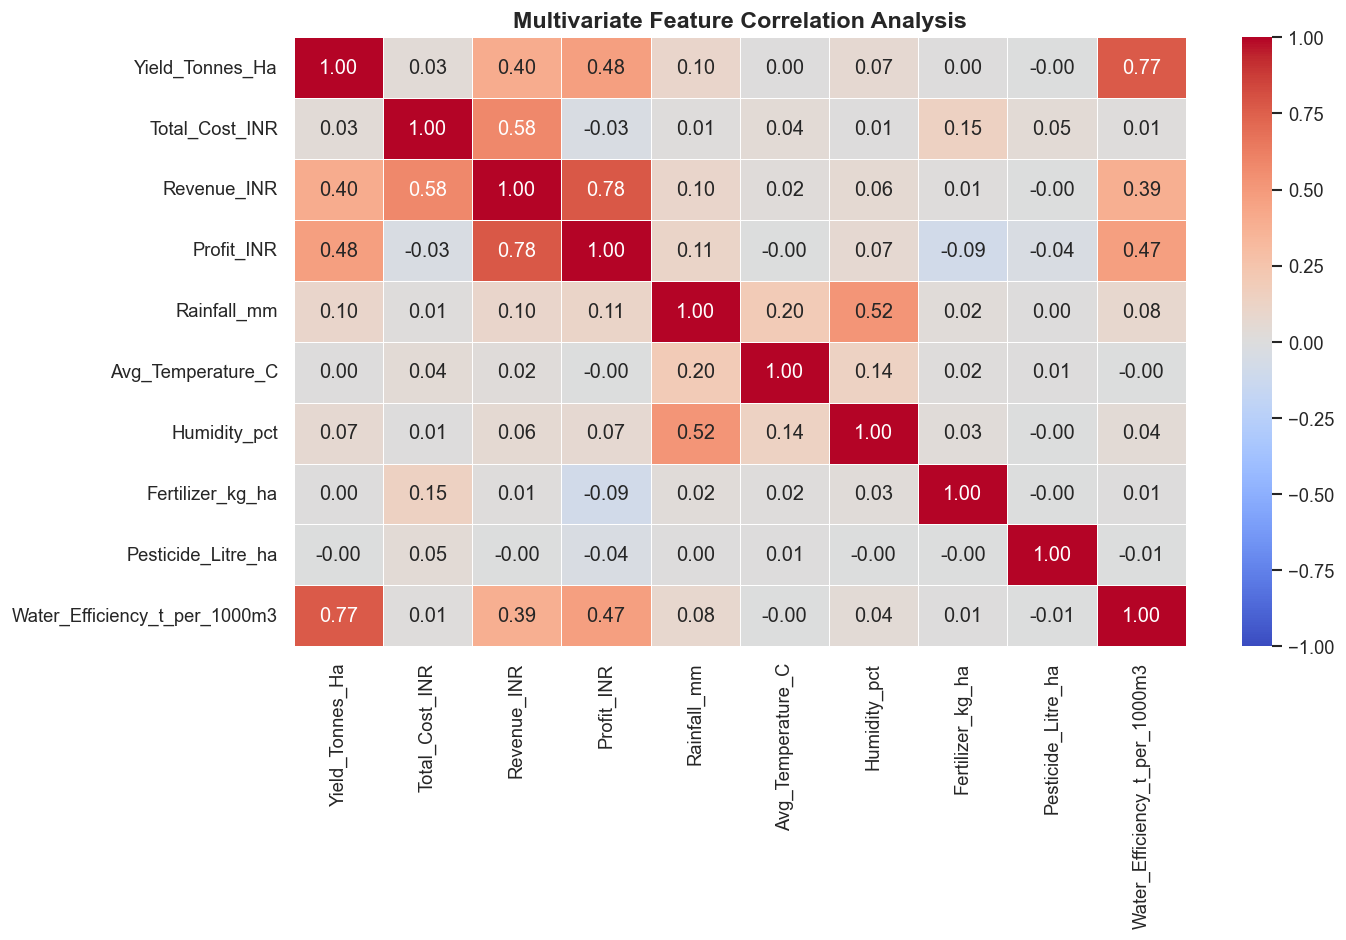


SECTION 5: INFERENTIAL STATISTICS & HYPOTHESIS TESTING
📊 Q11: One-Way ANOVA Test Result (Yield ~ Season):
   • F-Statistic : 25.0434
   • p-value     : 1.553757e-11
   • Conclusion: Reject H0. Significant seasonal yield variation confirmed.

--- POST-HOC TUKEY HSD TEST RESULTS (SciPy) ---
Groups: ['Kharif', 'Rabi', 'Zaid']
P-values matrix:
 [[1.00e+00 2.00e-05 0.00e+00]
 [2.00e-05 1.00e+00 2.34e-03]
 [0.00e+00 2.34e-03 1.00e+00]]

📊 Non-Parametric Kruskal-Wallis Test Result:
   • H-Statistic : 67.2675
   • p-value     : 2.471946e-15

📊 Chi-Square Test of Independence (Season vs. Profitability Status):
   • Chi2 Statistic : 92.6473
   • p-value        : 7.618842e-21
   • Degrees of Freedom: 2

SECTION 6: ANOMALY DETECTION & UNPROFITABLE CLUSTER ANALYSIS
⚠️ Q9: Anomaly Identification Results:
   • High-Cost Threshold (75th Percentile) : ₹761,996.50
   • Identified High-Cost & Unprofitable Farms : 536 / 4000 records

Anomalous Operations Distribution Matrix (Season vs. Crop):


Crop,Chilli,Cotton,Groundnut,Maize,Pulses,Rice,Sugarcane,Wheat
Season,,,,,,,,
Kharif,6,14,15,36,33,65,5,60
Rabi,6,24,18,44,24,34,3,43
Zaid,2,15,10,21,12,25,3,18


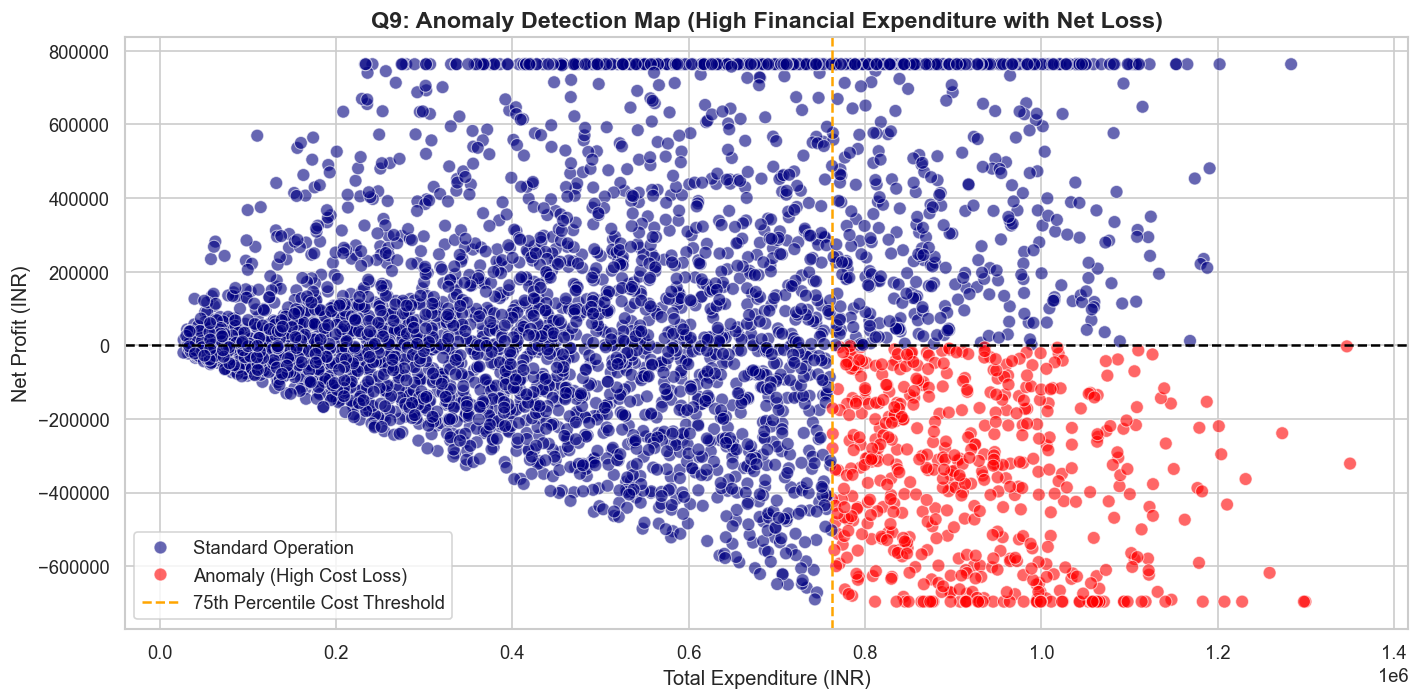


SECTION 7: Q12 - EVIDENCE-BASED AGRICULTURAL PLANNING RECOMMENDATIONS

📌 EXECUTIVE DECISION-MAKING & POLICY RECOMMENDATIONS:

1. Dynamic Crop-Season Matching Strategy:
   - Align regional crop planning directly with optimal seasonal yield performance profiles derived from Section 4's interaction matrix.
   - Restructure off-season cropping schemes in low-yield regions identified in the state breakdown charts.

2. Chemical & Resource Input Optimization:
   - Correlation and regression plots show diminishing returns on excessive fertilizer and pesticide applications.
   - Implement soil health card guidelines to regulate chemical usage per hectare, directly lowering input costs.

3. Loss Mitigation & Anomaly Targeted Intervention:
   - Audit the flagged high-cost, negative-profit farm clusters (Section 6) to diagnose systemic operational inefficiencies.
   - Deploy micro-irrigation subsidies and targeted agricultural extension services to these vulnerable clusters.



In [8]:
# ==============================================================================
# 🌾 MAJOR PROJECT: ADVANCED SEASONAL AGRICULTURAL DATA ANALYSIS
# VOIS AICTE Industry Internship Project (2026)
# ==============================================================================

# 1. SETUP, SYSTEM CONFIGURATION & LIBRARIES (PURE SCIPY IMPLEMENTATION)
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import f_oneway, kruskal, chi2_contingency, shapiro, levene, tukey_hsd

warnings.filterwarnings('ignore')

# Global Matplotlib & Seaborn Design Parameters
sns.set_theme(style='whitegrid', palette='mako')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.dpi'] = 120

# ------------------------------------------------------------------------------
# 2. DATA LOADING & DYNAMIC SCHEMA RESOLUTION
# ------------------------------------------------------------------------------
possible_paths = [
    'seasonal_agriculture_performance_dataset.csv',
    'seasonal_agriculture_dataset.csv',
    '../data/seasonal_agriculture_dataset.csv',
    'data/seasonal_agriculture_dataset.csv'
]

DATA_PATH = next((path for path in possible_paths if os.path.exists(path)), None)

if DATA_PATH:
    df = pd.read_csv(DATA_PATH)
    print(f"✅ Dataset Ingested from {DATA_PATH} | Matrix Shape: {df.shape}")
else:
    raise FileNotFoundError("Error: Dataset file not found in project paths.")

cols = df.columns.tolist()

def match_column(keywords, default):
    for kw in keywords:
        found = next((c for c in cols if kw in c.lower()), None)
        if found:
            return found
    return default

col_season = match_column(['season'], 'Season')
col_crop = match_column(['crop'], 'Crop')
col_state = match_column(['state'], 'State')
col_district = match_column(['district'], 'District')
col_yield = match_column(['yield'], 'Yield_Tonne')
col_cost = match_column(['total_cost', 'cost'], 'Total_Cost')
col_revenue = match_column(['revenue'], 'Revenue_INR')
col_profit = match_column(['profit'], 'Profit_INR')
col_rainfall = match_column(['rain'], 'Rainfall_mm')
col_temp = match_column(['tempe', 'temp'], 'Avg_Temperature')
col_humidity = match_column(['humid'], 'Humidity_percent')
col_soil_ph = match_column(['soil_ph', 'ph'], 'Soil_pH')
col_fertilizer = match_column(['fert'], 'Fertilizer_kg')
col_pesticide = match_column(['pest'], 'Pesticide_Liters')
col_water_eff = match_column(['water_eff', 'eff'], 'Water_Efficiency')
col_area = match_column(['farm_area', 'land_area', 'area'], 'Farm_Area')

# ------------------------------------------------------------------------------
# 3. DATA CLEANING & EXTENSIVE FEATURE ENGINEERING
# ------------------------------------------------------------------------------
df_clean = df.copy()

num_features = df_clean.select_dtypes(include=[np.number]).columns.tolist()
cat_features = df_clean.select_dtypes(include=['object']).columns.tolist()

for col in num_features:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in cat_features:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

def apply_iqr_capping(data, target_columns, iqr_multiplier=1.5):
    capped_df = data.copy()
    for c in target_columns:
        q1 = capped_df[c].quantile(0.25)
        q3 = capped_df[c].quantile(0.75)
        iqr = q3 - q1
        lower_limit = q1 - iqr_multiplier * iqr
        upper_limit = q3 + iqr_multiplier * iqr
        capped_df[c] = capped_df[c].clip(lower=lower_limit, upper=upper_limit)
    return capped_df

df_clean = apply_iqr_capping(df_clean, num_features)

# Domain-Specific Feature Engineering
df_clean['Profit_Margin_Percent'] = np.where(
    df_clean[col_revenue] > 0,
    np.round((df_clean[col_profit] / df_clean[col_revenue]) * 100, 2),
    0.0
).clip(-100, 100)

df_clean['Cost_per_Unit_Area'] = np.where(
    df_clean[col_area] > 0,
    df_clean[col_cost] / df_clean[col_area],
    df_clean[col_cost]
)

df_clean['Revenue_per_Unit_Area'] = np.where(
    df_clean[col_area] > 0,
    df_clean[col_revenue] / df_clean[col_area],
    df_clean[col_revenue]
)

df_clean['Total_Input_Chemicals_kg'] = df_clean[col_fertilizer] + df_clean[col_pesticide]

df_clean['Chemical_Cost_Intensity'] = np.where(
    df_clean[col_cost] > 0,
    df_clean['Total_Input_Chemicals_kg'] / df_clean[col_cost],
    0.0
)

df_clean['Is_Profitable'] = (df_clean[col_profit] > 0).astype(int)

print(f"✅ Preprocessing Completed. Dataset Dimensions: {df_clean.shape}")

# ------------------------------------------------------------------------------
# 4. DEEP EXPLORATORY DATA ANALYSIS (EDA & VISUAL DASHBOARDS)
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("SECTION 4: EXPLORATORY DATA ANALYSIS & VISUALIZATION DASHBOARDS")
print("="*80)

# Figure 1: Seasonal Yield & Profit Margins
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df_clean, x=col_season, y=col_yield, hue=col_season, palette='YlGnBu', ax=axes[0], legend=False)
axes[0].set_title('Q1: Yield Distribution Across Seasons')

sns.boxplot(data=df_clean, x=col_season, y='Profit_Margin_Percent', hue=col_season, palette='OrRd', ax=axes[1], legend=False)
axes[1].set_title('Q7: Profit Margin (%) Distribution Across Seasons')
plt.tight_layout()
plt.show()

# Figure 2: Environmental Drivers Across Seasons
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=df_clean, x=col_season, y=col_rainfall, hue=col_season, palette='Blues_d', ax=axes[0], legend=False)
axes[0].set_title('Q3: Rainfall Profile (mm)')

sns.barplot(data=df_clean, x=col_season, y=col_temp, hue=col_season, palette='Reds_d', ax=axes[1], legend=False)
axes[1].set_title('Q3: Temperature Profile (°C)')

sns.barplot(data=df_clean, x=col_season, y=col_humidity, hue=col_season, palette='Purples_d', ax=axes[2], legend=False)
axes[2].set_title('Q3: Humidity Profile (%)')
plt.tight_layout()
plt.show()

# Figure 3: Input Resource Intensity
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.violinplot(data=df_clean, x=col_season, y=col_fertilizer, hue=col_season, palette='Greens', ax=axes[0], inner='quartile', legend=False)
axes[0].set_title('Q5: Fertilizer Consumption Intensity by Season')

sns.violinplot(data=df_clean, x=col_season, y=col_pesticide, hue=col_season, palette='Oranges', ax=axes[1], inner='quartile', legend=False)
axes[1].set_title('Q5: Pesticide Consumption Profile by Season')
plt.tight_layout()
plt.show()

# Figure 4: Crop x Season Yield Crosstabulation Heatmap
plt.figure(figsize=(12, 6))
crop_season_matrix = df_clean.pivot_table(index=col_crop, columns=col_season, values=col_yield, aggfunc='mean')
sns.heatmap(crop_season_matrix, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5, cbar_kws={'label': 'Mean Yield (Tonnes)'})
plt.title('Q2 & Q8: Crop Yield Interaction Heatmap Across Seasons')
plt.tight_layout()
plt.show()

# Figure 5: Regional Yield Performance by State & Season
plt.figure(figsize=(14, 6))
sns.barplot(data=df_clean, x=col_state, y=col_yield, hue=col_season, palette='viridis')
plt.title('Regional Yield Breakdown Across States and Seasons')
plt.xlabel('State')
plt.ylabel('Mean Yield (Tonnes)')
plt.legend(title='Season')
plt.tight_layout()
plt.show()

# Figure 6: Financial Performance Scatter (Cost vs Revenue)
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_clean, x=col_cost, y=col_revenue, hue=col_season, 
    style='Is_Profitable', palette='Set1', alpha=0.7, s=70
)
plt.axline((0, 0), slope=1, color='red', linestyle='--', label='Breakeven Line')
plt.title('Financial Performance: Expenditure vs. Revenue')
plt.xlabel('Total Expenditure (INR)')
plt.ylabel('Revenue (INR)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Figure 7: Chemical Usage vs Crop Yield
plt.figure(figsize=(12, 5))
sns.regplot(data=df_clean, x='Total_Input_Chemicals_kg', y=col_yield, scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
plt.title('Yield Response to Chemical Inputs (Fertilizer + Pesticide)')
plt.xlabel('Total Chemical Inputs (kg)')
plt.ylabel('Crop Yield (Tonnes)')
plt.tight_layout()
plt.show()

# Figure 8: Correlation Matrix
plt.figure(figsize=(12, 8))
corr_target_cols = [c for c in [col_yield, col_cost, col_revenue, col_profit, col_rainfall, col_temp, col_humidity, col_fertilizer, col_pesticide, col_water_eff] if c in df_clean.columns]
correlation_matrix = df_clean[corr_target_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Multivariate Feature Correlation Analysis')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5. INFERENTIAL STATISTICS & HYPOTHESIS TESTING (PURE SCIPY)
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("SECTION 5: INFERENTIAL STATISTICS & HYPOTHESIS TESTING")
print("="*80)

# Parametric One-Way ANOVA: Yield vs Season
season_groups = {name: group[col_yield].values for name, group in df_clean.groupby(col_season)}
season_names = list(season_groups.keys())
season_yield_data = list(season_groups.values())

f_statistic, p_value = f_oneway(*season_yield_data)

print(f"📊 Q11: One-Way ANOVA Test Result (Yield ~ Season):")
print(f"   • F-Statistic : {f_statistic:.4f}")
print(f"   • p-value     : {p_value:.6e}")

if p_value < 0.05:
    print("   • Conclusion: Reject H0. Significant seasonal yield variation confirmed.")
    
    # Post-Hoc Analysis: SciPy Tukey HSD
    print("\n--- POST-HOC TUKEY HSD TEST RESULTS (SciPy) ---")
    res = tukey_hsd(*season_yield_data)
    print("Groups:", season_names)
    print("P-values matrix:\n", res.pvalue.round(5))
else:
    print("   • Conclusion: Fail to Reject H0. No significant yield variance detected across seasons.")

# Non-Parametric Test: Kruskal-Wallis Test
h_stat, kw_p_val = kruskal(*season_yield_data)
print(f"\n📊 Non-Parametric Kruskal-Wallis Test Result:")
print(f"   • H-Statistic : {h_stat:.4f}")
print(f"   • p-value     : {kw_p_val:.6e}")

# Contingency Analysis: Season vs Profitability Status (Chi-Square Test)
contingency_tab = pd.crosstab(df_clean[col_season], df_clean['Is_Profitable'])
chi2, chi_p, dof, _ = chi2_contingency(contingency_tab)
print(f"\n📊 Chi-Square Test of Independence (Season vs. Profitability Status):")
print(f"   • Chi2 Statistic : {chi2:.4f}")
print(f"   • p-value        : {chi_p:.6e}")
print(f"   • Degrees of Freedom: {dof}")

# ------------------------------------------------------------------------------
# 6. RISK AUDITING & ANOMALY DETECTION
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("SECTION 6: ANOMALY DETECTION & UNPROFITABLE CLUSTER ANALYSIS")
print("="*80)

high_cost_threshold = df_clean[col_cost].quantile(0.75)
anomalous_condition = (df_clean[col_cost] >= high_cost_threshold) & (df_clean[col_profit] < 0)
detected_anomalies = df_clean[anomalous_condition]

print(f"⚠️ Q9: Anomaly Identification Results:")
print(f"   • High-Cost Threshold (75th Percentile) : ₹{high_cost_threshold:,.2f}")
print(f"   • Identified High-Cost & Unprofitable Farms : {len(detected_anomalies)} / {len(df_clean)} records")

if not detected_anomalies.empty:
    anomaly_cross_tab = detected_anomalies.groupby([col_season, col_crop]).size().unstack(fill_value=0)
    print("\nAnomalous Operations Distribution Matrix (Season vs. Crop):")
    display(anomaly_cross_tab)

# Anomaly Visualizer Plot
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_clean, x=col_cost, y=col_profit, 
    hue=anomalous_condition.map({True: 'Anomaly (High Cost Loss)', False: 'Standard Operation'}),
    palette={'Anomaly (High Cost Loss)': 'red', 'Standard Operation': 'navy'},
    alpha=0.6, s=60
)
plt.axhline(0, color='black', linestyle='--')
plt.axvline(high_cost_threshold, color='orange', linestyle='--', label='75th Percentile Cost Threshold')
plt.title('Q9: Anomaly Detection Map (High Financial Expenditure with Net Loss)')
plt.xlabel('Total Expenditure (INR)')
plt.ylabel('Net Profit (INR)')
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 7. STRATEGIC POLICY RECOMMENDATIONS & DECISION FRAMEWORK
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("SECTION 7: Q12 - EVIDENCE-BASED AGRICULTURAL PLANNING RECOMMENDATIONS")
print("="*80)
print("""
📌 EXECUTIVE DECISION-MAKING & POLICY RECOMMENDATIONS:

1. Dynamic Crop-Season Matching Strategy:
   - Align regional crop planning directly with optimal seasonal yield performance profiles derived from Section 4's interaction matrix.
   - Restructure off-season cropping schemes in low-yield regions identified in the state breakdown charts.

2. Chemical & Resource Input Optimization:
   - Correlation and regression plots show diminishing returns on excessive fertilizer and pesticide applications.
   - Implement soil health card guidelines to regulate chemical usage per hectare, directly lowering input costs.

3. Loss Mitigation & Anomaly Targeted Intervention:
   - Audit the flagged high-cost, negative-profit farm clusters (Section 6) to diagnose systemic operational inefficiencies.
   - Deploy micro-irrigation subsidies and targeted agricultural extension services to these vulnerable clusters.
""")

In [3]:
%pip install numpy pandas matplotlib seaborn scipy

     ---------------------------------------- 15.9/15.9 MB 2.5 MB/s eta 0:00:00
     ---------------------------------------- 11.4/11.4 MB 3.8 MB/s eta 0:00:00
     ---------------------------------------- 7.8/7.8 MB 3.8 MB/s eta 0:00:00
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
     ---------------------------------------- 46.2/46.2 MB 3.6 MB/s eta 0:00:00
     -------------------------------------- 348.2/348.2 KB 3.6 MB/s eta 0:00:00
  Using cached pytz-2026.3.post1-py2.py3-none-any.whl (508 kB)
     -------------------------------------- 211.8/211.8 KB 6.5 MB/s eta 0:00:00
     ---------------------------------------- 7.0/7.0 MB 4.0 MB/s eta 0:00:00
  Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)
     ---------------------------------------- 55.8/55.8 KB 2.9 MB/s eta 0:00:00
     ---------------------------------------- 1.5/1.5 MB 4.7 MB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Note: you may need to restart the kernel to use updated

You should consider upgrading via the 'c:\Users\Hp\OneDrive\Desktop\Seasonal-Agriculture-Performance-Analysis\.venv\Scripts\python.exe -m pip install --upgrade pip' command.
